# Lab 2: Kiểm Định ADF & Chuẩn Bị Mô Hình ARIMA / SARIMA
---
## Bài 1: Khám phá dữ liệu (EDA)
- Load dữ liệu
- Chuyển date thành index thời gian
- Vẽ đồ thị chuỗi thời gian

**Câu hỏi cần trả lời:**
- Chuỗi có xu hướng không?
- Có dấu hiệu mùa vụ không?
- Chuỗi có khả năng dừng không?

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# Tắt cảnh báo FutureWarning từ statsmodels
warnings.filterwarnings('ignore', category=FutureWarning)

from statsmodels.tsa.stattools import adfuller

# Cấu hình giao diện biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

### 1. Load dữ liệu

In [30]:
data_path = '../data/raw/a10.csv'  # Hoặc 'data/raw/a10.csv' tùy thư mục làm việc

df = pd.read_csv(data_path)

print("=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ===")
display(df.head())

print("\n=== THÔNG TIN DỮ LIỆU BAN ĐẦU ===")
df.info()

print("\n=== THỐNG KÊ MÔ TẢ ===")
display(df.describe())

=== 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ===


,date,value
0,1991-07-01,3.526591
1,1991-08-01,3.180891
2,1991-09-01,3.252221
3,1991-10-01,3.611003
4,1991-11-01,3.565869



=== THÔNG TIN DỮ LIỆU BAN ĐẦU ===
<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    204 non-null    str    
 1   value   204 non-null    float64
dtypes: float64(1), str(1)
memory usage: 3.3 KB

=== THỐNG KÊ MÔ TẢ ===


,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


### 2. Chuyển date thành index thời gian

In [31]:
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)
df = df.asfreq('MS')  # Tần số theo tháng (Month Start)

print("Kiểu index:", type(df.index))
print("Tần số (Frequency):", df.index.freq)
print("Khoảng thời gian:", df.index.min().strftime('%Y-%m'), "đến", df.index.max().strftime('%Y-%m'))
display(df.head())

# Lưu dữ liệu sau khi set index vào data/processed/
os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/a10_processed.csv', index=True)
print("\n-> Đã lưu dữ liệu vào: data/processed/a10_processed.csv")

Kiểu index: <class 'pandas.DatetimeIndex'>
Tần số (Frequency): <MonthBegin>
Khoảng thời gian: 1991-07 đến 2008-06


,value
date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869



-> Đã lưu dữ liệu vào: data/processed/a10_processed.csv


### 3. Vẽ đồ thị chuỗi thời gian

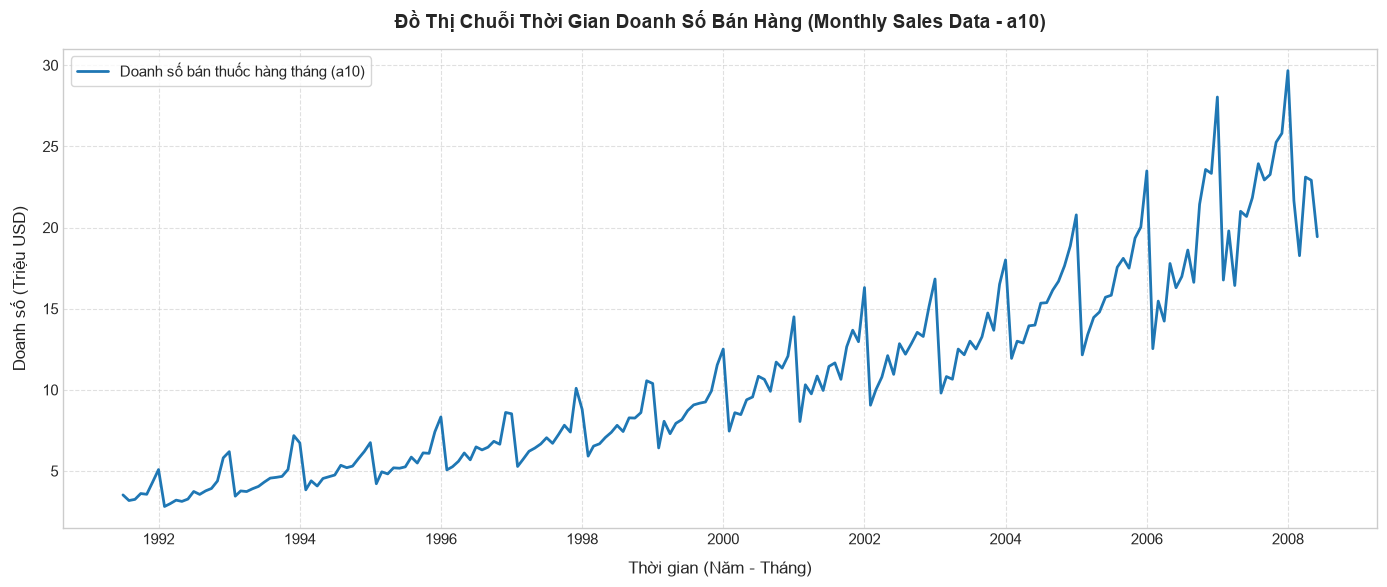

In [32]:
plt.figure(figsize=(14, 6))
plt.plot(df.index, df['value'], color='#1f77b4', linewidth=2, label='Doanh số bán thuốc hàng tháng (a10)')

plt.title('Đồ Thị Chuỗi Thời Gian Doanh Số Bán Hàng (Monthly Sales Data - a10)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Thời gian (Năm - Tháng)', fontsize=12, labelpad=10)
plt.ylabel('Doanh số (Triệu USD)', fontsize=12, labelpad=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### Trả lời câu hỏi:

1. **Chuỗi có xu hướng không?**
   - **Có**: Chuỗi có **xu hướng tăng rõ rệt (Upward Trend)** theo thời gian từ năm 1991 đến 2008.

2. **Có dấu hiệu mùa vụ không?**
   - **Có**: Xuất hiện tính chu kỳ/mùa vụ lặp lại đều đặn hàng năm ($s = 12$ tháng), đỉnh thường rơi vào tháng 12 - tháng 1 và đáy rơi vào tháng 2. Biên độ dao động mùa vụ tăng dần theo thời gian.

3. **Chuỗi có khả năng dừng không?**
   - **Không**: Chuỗi **không có tính dừng (Non-stationary)** vì trung bình (mean) tăng theo thời gian và phương sai (variance) thay đổi / biên độ dao động mùa vụ mở rộng dần theo thời gian.

---
## Bài 2: Kiểm định ADF trên chuỗi gốc
- Thực hiện kiểm định ADF cho chuỗi gốc
  - Giá trị ADF statistic
  - p-value
  - Kết luận: Dừng / Không dừng

**Câu hỏi cần trả lời:**
- $H_0$ của ADF là gì?
- p-value cho biết điều gì?
- Chuỗi có dừng không?

In [ ]:
def adf_test(series, name='Chuỗi'):
    """
    Thực hiện kiểm định Augmented Dickey-Fuller (ADF) và in kết quả chi tiết
    """
    series_clean = series.dropna()
    result = adfuller(series_clean, autolag='AIC')
    
    adf_stat = result[0]
    p_value = result[1]
    used_lag = result[2]
    n_obs = result[3]
    critical_values = result[4]
    
    print(f"==================================================")
    print(f"  KẾT QUẢ KIỂM ĐỊNH ADF CHO: {name.upper()}")
    print(f"==================================================")
    print(f"• Test Statistic (ADF) : {adf_stat:.6f}")
    print(f"• p-value              : {p_value:.6f}")
    print(f"• Số độ trễ đã dùng    : {used_lag}")
    print(f"• Số lượng quan sát    : {n_obs}")
    print(f"• Các giá trị tới hạn (Critical Values):")
    for level, value in critical_values.items():
        print(f"    - Mức {level:>3}: {value:.6f}")
    print(f"--------------------------------------------------")
    
    alpha = 0.05
    if p_value <= alpha:
        print(f" Kết luận: p-value <= {alpha} => BÁC BỎ H0.")
        print(f"==> Chuỗi '{name}' LÀ CHUỖI DỪNG (Stationary).")
        is_stationary = True
    else:
        print(f" Kết luận: p-value > {alpha} => KHÔNG THỂ BÁC BỎ H0.")
        print(f"==> Chuỗi '{name}' KHÔNG DỪNG (Non-Stationary).")
        is_stationary = False
    print(f"==================================================\n")
    
    return {
        'adf_stat': adf_stat,
        'p_value': p_value,
        'critical_values': critical_values,
        'is_stationary': is_stationary
    }

In [ ]:
adf_original = adf_test(df['value'], name='Chuỗi gốc a10 (Doanh số bán thuốc)')

  KẾT QUẢ KIỂM ĐỊNH ADF CHO: CHUỖI GỐC A10 (DOANH SỐ BÁN THUỐC)
• Test Statistic (ADF) : 3.145186
• p-value              : 1.000000
• Số độ trễ đã dùng    : 15
• Số lượng quan sát    : 188
• Các giá trị tới hạn (Critical Values):
    - Mức  1%: -3.465620
    - Mức  5%: -2.877040
    - Mức 10%: -2.575032
--------------------------------------------------
 Kết luận: p-value > 0.05 => KHÔNG THỂ BÁC BỎ H0.
==> Chuỗi 'Chuỗi gốc a10 (Doanh số bán thuốc)' KHÔNG DỪNG (Non-Stationary).



### Trả lời câu hỏi:

1. **$H_0$ của ADF là gì?**
   - Giả thuyết không ($H_0$): Chuỗi **KHÔNG DỪNG**.
   - Giả thuyết đối ($H_1$): Chuỗi **CÓ TÍNH DỪNG**.

2. **p-value cho biết điều gì?**
   - p-value phản ánh xác suất ủng hộ giả thuyết $H_0$. Với mức ý nghĩa chuẩn $\alpha = 0.05$:
     - Nếu **p-value $\le 0.05$**: Bác bỏ $H_0$ $\rightarrow$ Chuỗi DỪNG.
     - Nếu **p-value $> 0.05$**: Không thể bác bỏ $H_0$ $\rightarrow$ Chuỗi KHÔNG DỪNG.

3. **Chuỗi có dừng không?**
   - **Kết luận: Chuỗi gốc KHÔNG DỪNG (Non-Stationary)**.
   - Vì p-value $\approx 1.000000 > 0.05$ và giá trị Test Statistic ($+3.145$) lớn hơn nhiều so với các giá trị tới hạn Critical Values (ở mức 5% là $-2.88$), không bác bỏ $H_0$.